In [17]:
import numpy as np
import pandas as pd
import os 
i = 0
for _dirname, _, filenames in os.walk("/kaggle/input"):
    for filename in filenames:
        i += 1

print(i)

519


In [18]:
import os, librosa 
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import IPython.display as ipd
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow import keras
from keras.preprocessing.sequence import pad_sequences
from keras import layers, Sequential
from keras.utils import to_categorical
from keras.callbacks import EarlyStopping
import tensorflow_hub as hub

/kaggle/input/datasets/senaca/mimii-pump-sound-dataset/abnormal/00000014.wav


Text(0, 0.5, 'freq')

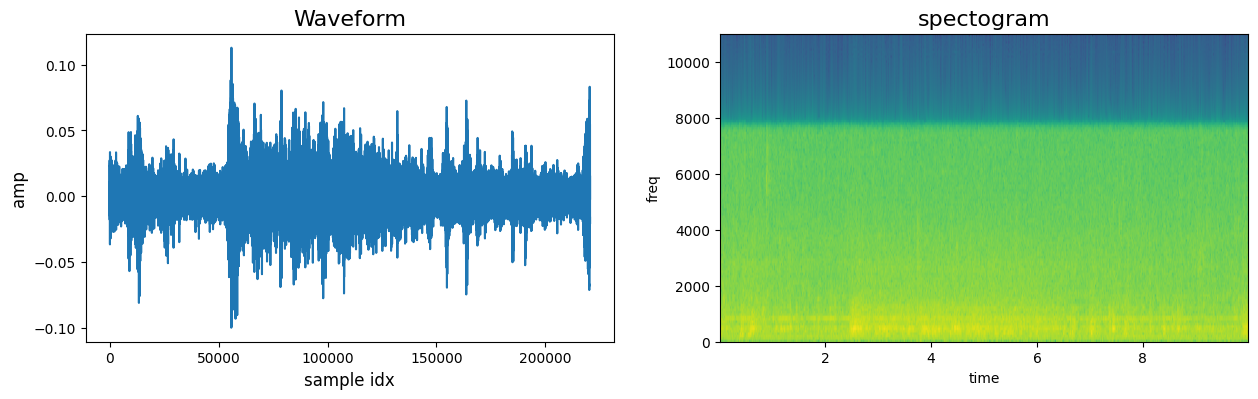

In [19]:
vg = hub.load("https://tfhub.dev/google/vggish/1")

file_audio = "/kaggle/input/datasets/senaca/mimii-pump-sound-dataset/abnormal/00000014.wav"
print(file_audio)
wf, sampleRate = librosa.load(file_audio)
ipd.display(ipd.Audio(wf, rate=sampleRate))

plt.figure(figsize=(15, 4))
plt.subplot(1, 2, 1)
plt.plot(wf)
plt.title("Waveform", fontsize=16)
plt.xlabel("sample idx", fontsize=12)
plt.ylabel("amp", fontsize=12)

plt.subplot(1, 2, 2)
plt.specgram(wf, Fs=sampleRate)
plt.title("spectogram", fontsize=16)
plt.xlabel("time")
plt.ylabel("freq")


In [ ]:
root = "/kaggle/input/datasets/senaca/mimii-pump-sound-dataset"
data = []

#extract features func
def extractFeatures(audioFile):
    try:
        wf, sampleRate = librosa.load(audioFile)
        wf, _ =  librosa.effects.trim(wf)
        return vg(wf).numpy()
    except:
        return None
        
for folder in os.listdir(root):
    folderPath = os.path.join(root, folder)

    for file in tqdm(os.listdir(folderPath), desc=f'processing folder {folder} '):
        filePath = os.path.join(folderPath, file)
        features = extractFeatures(filePath)
    
        if features is not None:
            data.append([features, folder])

processing folder abnormal : 100%|██████████| 138/138 [00:03<00:00, 36.60it/s]


/tmp/ipykernel_1149/1671060966.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=data['Class'], palette='viridis')


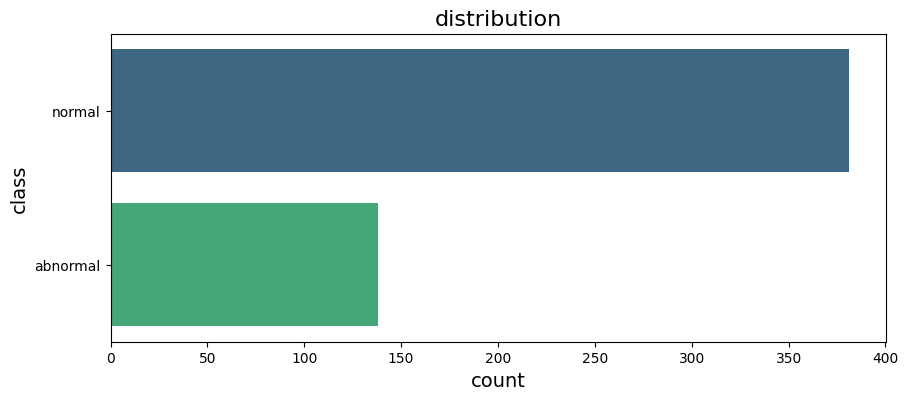

In [8]:
data = pd.DataFrame(data, columns=["Features", "Class"])
data.head()

plt.figure(figsize = (10, 4))
sns.countplot(y=data['Class'], palette='viridis')
plt.title("distribution", fontsize=16)
plt.xlabel("count", fontsize=14)
plt.ylabel("class", fontsize=14)
plt.show()

In [9]:
x = data["Features"].tolist()
x = pad_sequences(x, dtype="float32", padding="post", truncating="post")
x.shape

(519, 14, 128)

In [10]:
encoder = LabelEncoder()
y = encoder.fit_transform(data['Class'])
y = to_categorical(y)


In [11]:
trainX, testX, trainY, testY = train_test_split(x, y, random_state=0)


In [12]:
from tensorflow.keras import layers, Sequential

model = Sequential([layers.Conv2D(32, kernel_size=(3,3), activation="relu", padding="same",
                    input_shape=(14, 128, 1)),
                    layers.MaxPooling2D(),
                    layers.BatchNormalization(),
                    layers.Dropout(0.2),
                    layers.Conv2D(64, kernel_size=(3,3), activation="relu", padding="same"),
                    layers.MaxPooling2D(),
                    layers.BatchNormalization(),
                    layers.Dropout(0.2),
                    layers.Flatten(),
                    layers.Dense(64, activation="relu"), 
                    layers.Dropout(0.5),
                    layers.Dense(2, activation="softmax")
                   ])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 128, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 7, 64, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 7, 64, 32)      │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 7, 64, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 64, 64)      │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 3, 32, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 3, 32, 64)      │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 3, 32, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6144)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       393,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 412,610 (1.57 MB)

 Trainable params: 412,418 (1.57 MB)

 Non-trainable params: 192 (768.00 B)

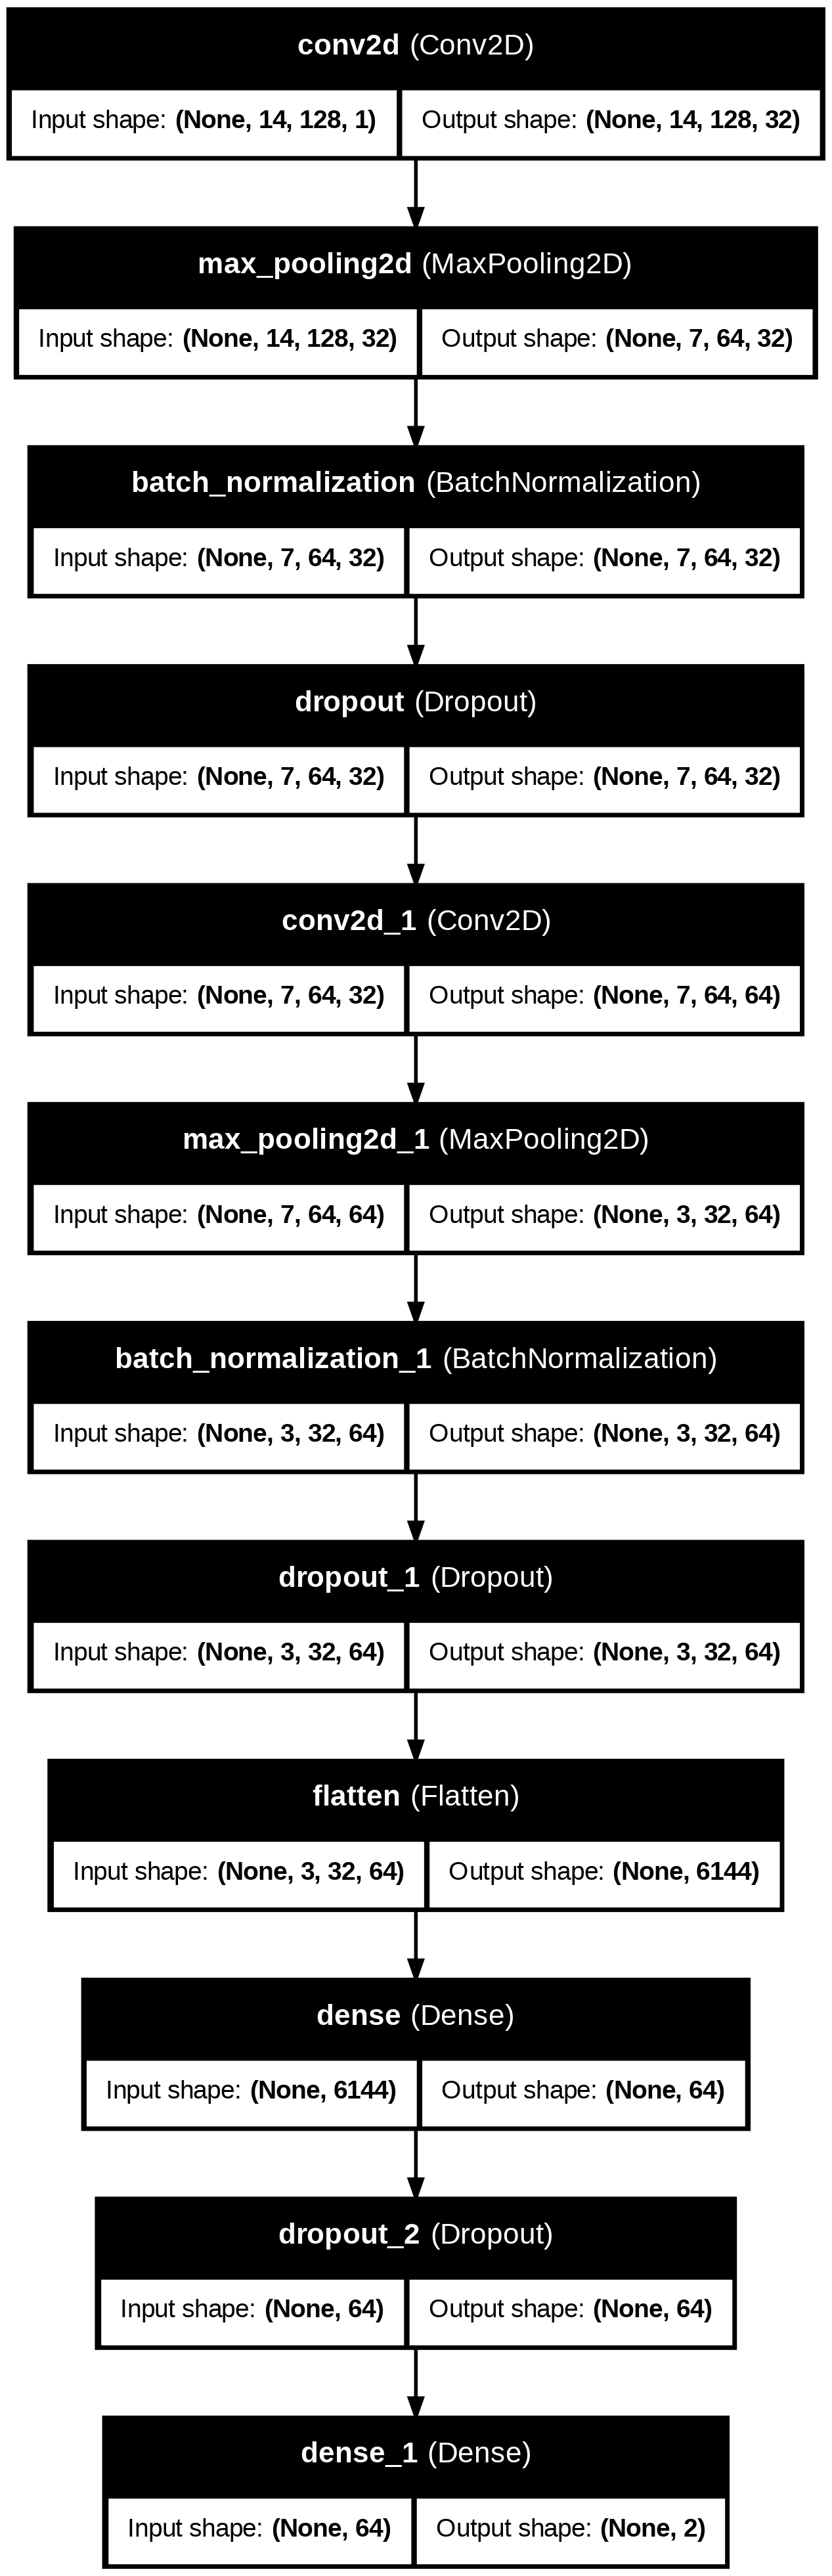

In [13]:
from keras.utils import plot_model

plot_model(model, to_file="model_plot.png", show_shapes=True, show_layer_names=True)

In [ ]:
earlyStop = EarlyStopping(
    monitor = 'val_accuracy',
    patience = 10,
    min_delta = 0.001,
    restore_best_weights=True
)


In [15]:
print(trainX.shape, trainY.shape)

hist = model.fit(
    trainX, trainY,
    validation_data=(testX, testY),
    epochs=10,
    callbacks=[earlyStop]
)

(389, 14, 128) (389, 2)
Epoch 1/10


2026-09-23 19:47:11.233872: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-23 19:47:11.381163: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


12/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7548 - loss: 0.8673 

I0000 00:00:1790192834.698409    1193 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


13/13 ━━━━━━━━━━━━━━━━━━━━ 13s 449ms/step - accuracy: 0.7738 - loss: 0.7460 - val_accuracy: 0.7615 - val_loss: 0.6026
Epoch 2/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8175 - loss: 0.4877 - val_accuracy: 0.8538 - val_loss: 0.6512
Epoch 3/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8252 - loss: 0.4680 - val_accuracy: 0.3923 - val_loss: 0.6929
Epoch 4/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8509 - loss: 0.4306 - val_accuracy: 0.2692 - val_loss: 0.8097
Epoch 5/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8483 - loss: 0.3753 - val_accuracy: 0.2692 - val_loss: 0.9768
Epoch 6/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8586 - loss: 0.3449 - val_accuracy: 0.2692 - val_loss: 1.4528
Epoch 7/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8406 - loss: 0.3619 - val_accuracy: 0.2692 - val_loss: 1.5032
Epoch 8/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8740 - loss: 0.3124 - val_accuracy: 0.2692 - val_loss: 

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8538 - loss: 0.6512 
85.38461327552795


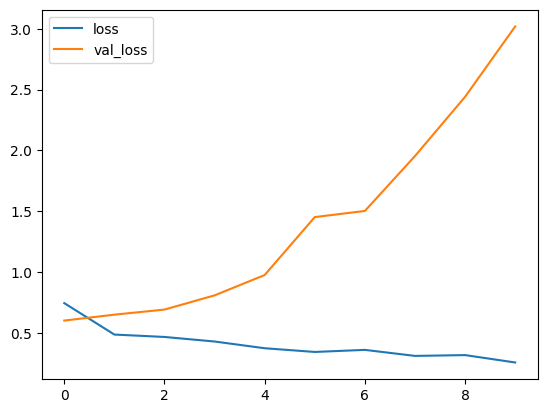

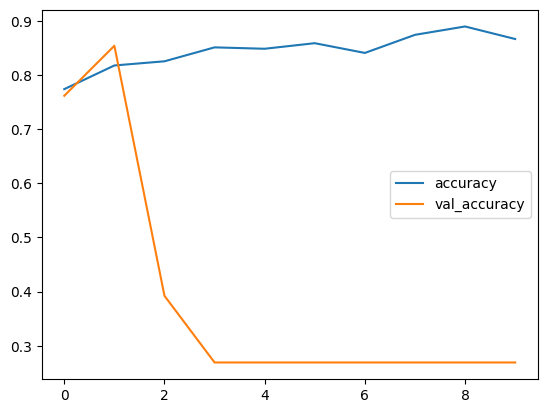

In [16]:
histDF = pd.DataFrame(hist.history)

histDF.loc[:, ["loss", 'val_loss']].plot()
histDF.loc[:, ["accuracy", "val_accuracy"]].plot()

score = model.evaluate(testX, testY)[1] * 100
print(score)